This Notebook only focus on two services procured.

Labour Hire Staff.

Residential Construction.

In [1]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

# from utilsforecast.plotting import plot_series
# from utilsforecast.evaluation import evaluate
# from utilsforecast.losses import *

import warnings
warnings.filterwarnings("ignore")

In [3]:
# pip install squarify

In [4]:
%%html
<style type="text/css">
.findings {background-color: #cdf7f7; padding: 15px;}
.notes {background-color: #d8f5c4; padding: 15px;}
</style>

In [5]:
# set global colors and styles
sns.set_palette('Blues_d')
# plt.xticks(fontsize = 12)
# plt.xticks(fontsize = 12)

# 1. Intial Setup - Load Data

In [6]:
data = pd.read_csv("Notifiable_Invoices_Register_20260804.csv")
data.head()

,Supplier Name,Supplier ABN,Reporting Entity,Publish Description,Date Invoice Received,Payment Date,Payment Amount,Contract Number
0,MARSH PTY LTD,86 004 651 512,ACTIA,INSURANCE BROKERAGE SERVICES,25/06/2019,19/07/2019,"$88,000.00",NaN
1,MARSH PTY LTD,86 004 651 512,ACTIA,RE-INSURANCE SERVICES,NaN,16/07/2015,"$1,100,000.00",NaN
2,LEGATO TECHNOLOGIES CONSULTING PTY LTD,70 659 368 975,ACT Electoral,SPLUNK SECURITY INFORMATION & EVENT MANAGEMENT...,05/07/2024,18/07/2024,"$29,172.00",NaN
3,BELLCHAMBERS BARRETT PTY LTD,14 942 509 138,ACTAO,PROFESSIONAL SERVICE FEES,07/09/2022,20/09/2022,"$31,014.12",NaN
4,MARSH PTY LTD,86 004 651 512,ACTIA,INSURANCE BROKERAGE SERVICES,09/07/2021,29/07/2021,"$263,902.65",NaN


In [7]:
data.shape

(124335, 8)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124335 entries, 0 to 124334
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Supplier Name          124334 non-null  object
 1   Supplier ABN           124289 non-null  object
 2   Reporting Entity       124329 non-null  object
 3   Publish Description    124331 non-null  object
 4   Date Invoice Received  105409 non-null  object
 5   Payment Date           124333 non-null  object
 6   Payment Amount         124281 non-null  object
 7   Contract Number        11460 non-null   object
dtypes: object(8)
memory usage: 7.6+ MB


In [9]:
data.isna().sum()

Supplier Name                 1
Supplier ABN                 46
Reporting Entity              6
Publish Description           4
Date Invoice Received     18926
Payment Date                  2
Payment Amount               54
Contract Number          112875
dtype: int64

<div class = "notes">
    <b>Notes</b>: Things I will do next.
    <ul>
        <li>Find out the observation with NaN in 'Supplier Name'.</li>
        <li>Remove spaces in 'Supplier ABN'. Keep the data type as object as the numbers are just unique identifiers.</li>
        <li>Find out the 6 observations with NaN in 'Reporting Entity'.</li>
        <li>Find out the 4 observations with NaN in 'Publish Description'.</li>
        <li>Change data types of both 'Date Invoice Received' and 'Payment Date' to dates.</li>
        <li>Find out the 2 observations with NaN in 'Payment Date'.</li>
        <li>Change the data type of 'Payment Amount' to float.</li>
        <li>Find out the 54 observations with NaN in 'Payment Amount'.</li>
        <li>Change all upper cases and replace spaces with _ in the column names.</li>
    </ul>
</div>

# 2. Data Wrangling

## 2.1 Change Column Names

In [10]:
# create a function to change column names

def clean_col_name(col_names):
    clean_col_names = []
    for col in col_names:
        col = col.lower().replace(' ', '_')
        clean_col_names.append(col)
    return clean_col_names

In [11]:
# run the function on our data
data.columns = clean_col_name(data.columns)

In [12]:
data.head()

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
0,MARSH PTY LTD,86 004 651 512,ACTIA,INSURANCE BROKERAGE SERVICES,25/06/2019,19/07/2019,"$88,000.00",NaN
1,MARSH PTY LTD,86 004 651 512,ACTIA,RE-INSURANCE SERVICES,NaN,16/07/2015,"$1,100,000.00",NaN
2,LEGATO TECHNOLOGIES CONSULTING PTY LTD,70 659 368 975,ACT Electoral,SPLUNK SECURITY INFORMATION & EVENT MANAGEMENT...,05/07/2024,18/07/2024,"$29,172.00",NaN
3,BELLCHAMBERS BARRETT PTY LTD,14 942 509 138,ACTAO,PROFESSIONAL SERVICE FEES,07/09/2022,20/09/2022,"$31,014.12",NaN
4,MARSH PTY LTD,86 004 651 512,ACTIA,INSURANCE BROKERAGE SERVICES,09/07/2021,29/07/2021,"$263,902.65",NaN


## 2.2 Change Data Types

### 2.2.1 supplier_abn

In [13]:
# remove spaces

data['supplier_abn'] = data['supplier_abn'].str.replace(' ','')


In [14]:
data['supplier_abn']

0         86004651512
1         86004651512
2         70659368975
3         14942509138
4         86004651512
             ...     
124330    77613902346
124331    75288172749
124332    89111470270
124333    20607773295
124334    89111470270
Name: supplier_abn, Length: 124335, dtype: object

### 2.2.2 date_invoice_received and payment_date

In [15]:
# parsing a 'DD/MM/YYYY' string structure and convert invalid strings into NaT (not a time) missing values

data['date_invoice_received'] = pd.to_datetime(data['date_invoice_received'], format = '%d/%m/%Y', errors = 'coerce')

data['payment_date'] = pd.to_datetime(data['payment_date'], format = '%d/%m/%Y', errors = 'coerce')

### 2.2.3 payment_amount

In [16]:
# remove $ and , 

data['payment_amount'] = data['payment_amount'].str.replace('$','')
data['payment_amount'] = data['payment_amount'].str.replace(',','')

# convert the data type to float
data['payment_amount'] = data['payment_amount'].astype(float)

In [17]:
# check data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124335 entries, 0 to 124334
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   supplier_name          124334 non-null  object        
 1   supplier_abn           124289 non-null  object        
 2   reporting_entity       124329 non-null  object        
 3   publish_description    124331 non-null  object        
 4   date_invoice_received  105409 non-null  datetime64[ns]
 5   payment_date           124333 non-null  datetime64[ns]
 6   payment_amount         124281 non-null  float64       
 7   contract_number        11460 non-null   object        
dtypes: datetime64[ns](2), float64(1), object(5)
memory usage: 7.6+ MB


## 2.3 Check null values

### 2.3.1 'supplier_name'

In [18]:
_data = data[data['supplier_name'].isna() ]
_data

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
28886,NaN,International,CHS,PUBLICATIONS & SUBSCRIPTIONS,2024-03-12,2024-03-15,174033.77,NaN


<div class = "notes">
   <b>Note</b>
    <br>In this case, I have value in supplier_abn. I can use supplier_abn to find the most frequent appreared supplier with the same supplier_abn.
    <br><b><i>Here is the value I could use to fill the missing value in 'supplier_name'.</i></b>
    <br>Fill the NaN in 'supplier_name' with the supplier appearing most often with the same supplier_abn. 
</div>

### 2.3.2 'supplier_abn'

In [19]:
_data = data[data['supplier_abn'].isna()]
_data

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
2229,BMJ PUBLISHING GROUP LTD,NaN,AHD,PUBLICATIONS,NaT,2016-12-19,26804.51,NaN
2508,BMJ PUBLISHING GROUP LTD,NaN,AHD,PUBLICATIONS,NaT,2015-12-24,31884.51,NaN
5811,"KREUGER CONSULTING, LLC",NaN,AHD,CONTRACTORS - SYSTEMS MODELLING FOR THE ACT,2021-07-19,2021-07-30,35719.21,NaN
6108,INFORMA UK LIMITED,NaN,AHD,PUBLICATIONS,NaT,2016-12-22,36899.47,NaN
6261,JODI JOHNSON-GLADING,NaN,AHD,RELOCATION COSTS,2024-12-04,2024-12-12,55000.00,NaN
11135,THE ADVISORY BOARD COMPANY,NaN,AHD,MEMBERSHIPS AND ASSOCIATIONS,NaT,2015-12-11,30732.00,NaN
11196,THE ADVISORY BOARD COMPANY,NaN,AHD,CONSULTANTS (MANAGEMENT),NaT,2016-11-17,33191.00,NaN
11660,THE ADVISORY BOARD COMPANY,NaN,AHD,CONSULTANTS (MANAGEMENT),NaT,2016-11-17,32000.00,NaN
23393,MCGRAW HILL LLC,NaN,CHS,PUBLICATIONS,2021-06-28,2021-07-23,33607.82,NaN
24960,PMOD TECHNOLOGIES LTD,NaN,CHS,IT SUPPORT,2019-12-16,2019-12-23,26702.21,NaN


<div class = "findings">
   <b>Findings</b>
    <br>Many of these invoices without supplier_abn appear to be from overseas suppliers.
</div>

<div class = "notes">
   <b>Note</b>
    <br>Overseas suppliers do not have ABN.
    <br>It is <b>NOT</b> legally required to provide ABN in invoices. More info here: https://sprintlaw.com.au/articles/run-a-business-without-an-abn/. 
    <br>Therefore, the data is not captured in a consistent manner.
    <br>I am happy with using just the supplier_name data. No further action is needed to fill the null values in supplier_abn.
</div>

### 2.3.2 'reporting_entity'

In [20]:
_data = data[data['reporting_entity'].isna() ]
_data

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
110720,AUDIT OFFICE PRICEWATERHOUSEC,52780433757,NaN,FINANCIAL AUDIT,NaT,2016-12-15,33000.00,NaN
110724,ICRCECONOMIC INSIGHTS,52060723631,NaN,ECONOMIC SERVICES RE WATER AND ELECTRICITY PRI...,NaT,2017-01-11,33000.00,NaN
110762,NORTHERN TRUST,62126279918,NaN,MASTER CUSTODY FEES,NaT,2015-07-29,36228.50,NaN
110764,AUDIT OFFICE PRICEWATERHOUSEC,52780433757,NaN,FINANCIAL AUDIT,NaT,2016-12-15,27500.00,NaN
110783,NORTHERN TRUST,62126279918,NaN,MASTER CUSTODY FEES,NaT,2015-07-24,35301.42,NaN
110791,ICRC ECONOMIC INSIGHTS,52060723631,NaN,ECONOMIC SERVICES RE WATER AND ELECTRICITY PRI...,NaT,2017-01-25,33000.00,NaN


<div class = "notes">
   <b>Note</b>
    <br>I want to use reporting_entity in the model. It is a key component in my model to understand how we can predict government spendings.
    <ul><b><i>Here are the values I will use to fill the missing values in 'reporting_entity'.</i></b>
        <li>I will fill the null values in reporting_entity by finding the reporting_entity who purchased most from the supplier. </li>
    </ul>
</div>

### 2.3.3 'publish_description'

In [21]:
_data = data[data['publish_description'].isna() ]
_data

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
1848,AUSTRALIAN NATIONAL UNIVERSITY,52234063906,AHD,NaN,NaT,2015-09-17,32484.76,NaN
60446,MSS SECURITY PTY LTD,29100573966,CSD,NaN,NaT,2016-09-15,27465.05,NaN
61774,SPECIALIST DIAGNOSTIC SERVICES PTY LTD,84007190043,CSD,NaN,NaT,2016-09-27,25197.04,NaN
92590,ACTEWAGL DISTRIBUTION,76670568688,TAMSD,NaN,NaT,2015-09-01,654469.69,NaN


<div class = "notes">
   <b>Note</b>
    <br>I want to use publish_description in the model. It may help the model to understand what goods or services ACT procures.
    <ul><b><i>Here are the values I will use to fill the missing values in 'publish_description'.</i></b>
        <li>I will fill the null values in publish_description by finding the most procured goods or services from the supplier. </li>
    </ul>
</div>

### 2.3.4 'payment_date'

In [22]:
_data = data[data['payment_date'].isna() ]
_data

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
72,IQON PTY LTD,14008595122,ACT Legal Aid,RENOVATION WORK AND FURNITURE,NaT,NaT,80475.34,NaN
31486,ARUP PTY LTD,18000966165,CMTEDD,SMART CITY OPPORTUNITY ASSESSMENT - FINAL REPORT,NaT,NaT,33000.00,NaN


<div class = "notes">
   <b>Note</b>
    <br>From the observations shown in the top 5 rows in the .head() function, I can't fill the missing values in payment_date of these two observations 72 and 31486 based on the neighbouring observations. The observations are not organised in the chronical order of payment dates.
    <br>The invoice received dates are also missing. I can't use them to extrapolate the payment dates either.
    <br><b><i>I will drop these two observations.</i></b>
</div>

### 2.3.5 'payment_amount'

In [23]:
_data = data[data['payment_amount'].isna() ]
_data

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
8040,NEC AUSTRALIA PTY LTD,86001217527,CED-TCO,NEXT GENERATION TICKETING SYSTEM,2026-03-20,2026-03-31,NaN,GS0314302
8041,NEC AUSTRALIA PTY LTD,86001217527,CED-TCO,NEXT GENERATION TICKETING SYSTEM,2026-03-20,2026-03-31,NaN,GS0314302
8042,NEC AUSTRALIA PTY LTD,86001217527,CED-TCO,NEXT GENERATION TICKETING SYSTEM,2026-02-13,2026-03-11,NaN,GS0314302
108758,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2025-02-17,2025-02-19,NaN,NaN
108826,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2024-04-19,2024-04-24,NaN,NaN
108846,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2025-02-17,2025-02-19,NaN,NaN
108881,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2024-04-09,2024-04-17,NaN,NaN
108918,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2025-04-24,2025-04-30,NaN,NaN
108919,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2024-10-14,2024-10-23,NaN,NaN
108980,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2025-05-02,2025-05-06,NaN,GS0314302


<div class = "notes">
   <b>Note</b>
    <br>All observations with missing values in payment amount are invoices from NEC Australia Pty Ltd. Let's find out more.
    <br>
    <br>
</div>

In [24]:
_data = data[data['supplier_name'] == 'NEC AUSTRALIA PTY LTD' ]
_data

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
8040,NEC AUSTRALIA PTY LTD,86001217527,CED-TCO,NEXT GENERATION TICKETING SYSTEM,2026-03-20,2026-03-31,NaN,GS0314302
8041,NEC AUSTRALIA PTY LTD,86001217527,CED-TCO,NEXT GENERATION TICKETING SYSTEM,2026-03-20,2026-03-31,NaN,GS0314302
8042,NEC AUSTRALIA PTY LTD,86001217527,CED-TCO,NEXT GENERATION TICKETING SYSTEM,2026-02-13,2026-03-11,NaN,GS0314302
35575,NEC AUSTRALIA PTY LTD,86001217527,CMTEDD,FINGERPRINT FOR SECURITY LICENCES,2025-02-04,2025-02-13,40043.59,NaN
78678,NEC AUSTRALIA PTY LTD,20093846925,ETD,ENVIRONMENTAL SUSTAINABILITY DESIGN PROGRAM - ...,2024-10-29,2024-11-19,56848.00,NaN
79256,NEC AUSTRALIA PTY LTD,95825767889,ETD,ACT SCHOOL SPORTS SERVICE AGREEMENT INSTALMENT...,2024-11-07,2024-11-12,242396.00,NaN
108758,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2025-02-17,2025-02-19,NaN,NaN
108826,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2024-04-19,2024-04-24,NaN,NaN
108846,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2025-02-17,2025-02-19,NaN,NaN
108881,NEC AUSTRALIA PTY LTD,86001217527,TCCS-TCO,NEXT GENERATION TICKETING SYSTEM,2024-04-09,2024-04-17,NaN,NaN


<div class = "findings">
    <b>Findings:</b>
    <br>It seems that all payments to NEC Australia that have missing values relates to 'NEXT GENERATION TICKETING SYSTEM'.
    <br>After digging through the internet, Next Generation Ticketing System is a multi-million dollar project.
    <br>Here is the link to the contract GS03143302: https://www.tenders.act.gov.au/contract/view?id=204268. 
    <br>
</div>

<div class = "notes">
   <b>Note</b>
    <br>I am guessing one possible reason for the missing values in the payments relating to Next Generation Ticketing System may be commercial sensitivity.
    <br>Sometimes, a large infrastructure project will not publish financials before the final phase.
    <br><b><i>I will drop these observations with missing values in payment_amount.</i></b>
</div>

## 2.4 Fill missing values

In [25]:
# create a copy of the data
data_clean = data.copy(deep = True)

In [26]:
# create a function to find the most frequent values
def find_mode_for_na(dataframe, lookupcol, targetcol):
    mode_vals = {lookupcol:[],targetcol:[]}
    lookup_val = dataframe[dataframe[targetcol].isna()][lookupcol]
    index = list(lookup_val.index)
    for x in lookup_val:
        if x is None:
            mode_val == None
        else:
            mode_val = dataframe[dataframe[lookupcol] == x][targetcol].mode()[0] # get the first mode value
        mode_vals[lookupcol].append(x)
        mode_vals[targetcol].append(mode_val)
    mode_df = pd.DataFrame(mode_vals, index = index)
    return mode_df

In [27]:
# create a function to fill the null value

def fill_na(dataframe, targetcol, fillvalue):
    dataframe.loc[dataframe[targetcol].isna(), targetcol] = dataframe.loc[dataframe[targetcol].isna()].index.map(fillvalue[targetcol])
    return

<div class = "notes">
   <b>Note</b>
    <br>It seems that this missing supplier_name only happened at the early stage of this dataset when it was first introduced. 
    <br>I don't expect it would happen in the future.
    <br>If it does happen, I'll fill it with the most frequent value based on the same supplier_abn value.
</div>

### 2.4.1 Fill 'supplier_name'

In [28]:
# use the function find_mode_for_na() to find mode of suppliers to fill the null value
fill_supplier = find_mode_for_na(data_clean, 'supplier_abn', 'supplier_name')

In [29]:
fill_supplier

,supplier_abn,supplier_name
28886,International,ELSEVIER


In [30]:
fill_supplier.index

Index([28886], dtype='int64')

In [31]:
# use the function fill_na() to fill the null value
data_clean.loc[data_clean['supplier_name'].isna(),'supplier_name'] = data_clean[data_clean['supplier_name'].isna()].index.map(fill_supplier['supplier_name'])

In [32]:
data_clean.loc[28886,'supplier_name']

'ELSEVIER'

In [33]:
data_clean.head()

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
0,MARSH PTY LTD,86004651512,ACTIA,INSURANCE BROKERAGE SERVICES,2019-06-25,2019-07-19,88000.00,NaN
1,MARSH PTY LTD,86004651512,ACTIA,RE-INSURANCE SERVICES,NaT,2015-07-16,1100000.00,NaN
2,LEGATO TECHNOLOGIES CONSULTING PTY LTD,70659368975,ACT Electoral,SPLUNK SECURITY INFORMATION & EVENT MANAGEMENT...,2024-07-05,2024-07-18,29172.00,NaN
3,BELLCHAMBERS BARRETT PTY LTD,14942509138,ACTAO,PROFESSIONAL SERVICE FEES,2022-09-07,2022-09-20,31014.12,NaN
4,MARSH PTY LTD,86004651512,ACTIA,INSURANCE BROKERAGE SERVICES,2021-07-09,2021-07-29,263902.65,NaN


### 2.4.2 Fill 'reporting_entity'

In [34]:
# use the function find_mode_for_na() to find mode to fill the null value
fill_reporting = find_mode_for_na(data_clean, 'supplier_abn', 'reporting_entity')

<div class = "notes">
    <b>Notes:</b>
    <br>For some unknown reason, the function didn't work when I used supplier_name as the lookupcol. It returned key error 0.
    <br>But it worked when using supplier_abn. It is a good enough substitute for supplier_name as the lookupcol.
</div>

In [35]:
fill_reporting

,supplier_abn,reporting_entity
110720,52780433757,MPC
110724,52060723631,ICRC
110762,62126279918,CMTEDD-TBA
110764,52780433757,MPC
110783,62126279918,CMTEDD-TBA
110791,52060723631,ICRC


In [36]:
# use the function fill_na() to fill the null value
fill_na(data_clean, 'reporting_entity', fill_reporting)

In [37]:
data_clean.head()

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
0,MARSH PTY LTD,86004651512,ACTIA,INSURANCE BROKERAGE SERVICES,2019-06-25,2019-07-19,88000.00,NaN
1,MARSH PTY LTD,86004651512,ACTIA,RE-INSURANCE SERVICES,NaT,2015-07-16,1100000.00,NaN
2,LEGATO TECHNOLOGIES CONSULTING PTY LTD,70659368975,ACT Electoral,SPLUNK SECURITY INFORMATION & EVENT MANAGEMENT...,2024-07-05,2024-07-18,29172.00,NaN
3,BELLCHAMBERS BARRETT PTY LTD,14942509138,ACTAO,PROFESSIONAL SERVICE FEES,2022-09-07,2022-09-20,31014.12,NaN
4,MARSH PTY LTD,86004651512,ACTIA,INSURANCE BROKERAGE SERVICES,2021-07-09,2021-07-29,263902.65,NaN


In [38]:
data_clean.iloc[110762]

supplier_name                 NORTHERN TRUST
supplier_abn                     62126279918
reporting_entity                  CMTEDD-TBA
publish_description      MASTER CUSTODY FEES
date_invoice_received                    NaT
payment_date             2015-07-29 00:00:00
payment_amount                       36228.5
contract_number                          NaN
Name: 110762, dtype: object

### 2.4.3 Fill 'publish_description'

In [39]:
# use the function find_mode_for_na() to find mode to fill the null value
fill_description = find_mode_for_na(data_clean, 'supplier_name', 'publish_description')

In [40]:
# use the function fill_na() to fill the null value
fill_na(data_clean, 'publish_description', fill_description)

In [41]:
data_clean.iloc[1848]

supplier_name            AUSTRALIAN NATIONAL UNIVERSITY
supplier_abn                                52234063906
reporting_entity                                    AHD
publish_description                SURVEYS AND RESEARCH
date_invoice_received                               NaT
payment_date                        2015-09-17 00:00:00
payment_amount                                 32484.76
contract_number                                     NaN
Name: 1848, dtype: object

### 2.4.4 Handle missing values in 'payment_date'

In [42]:
# drop the rows when payment date is null
data_clean = data_clean.drop(data_clean[data_clean['payment_date'].isna()].index)

### 2.4.5 Handle missing values in 'payment_amount'

In [43]:
# drop the rows when payment amount is null
data_clean = data_clean.drop(data_clean[data_clean['payment_amount'].isna()].index)

## 3. Explore Data Analysis

In [44]:
data_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 124279 entries, 0 to 124334
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   supplier_name          124279 non-null  object        
 1   supplier_abn           124233 non-null  object        
 2   reporting_entity       124279 non-null  object        
 3   publish_description    124279 non-null  object        
 4   date_invoice_received  105355 non-null  datetime64[ns]
 5   payment_date           124279 non-null  datetime64[ns]
 6   payment_amount         124279 non-null  float64       
 7   contract_number        11438 non-null   object        
dtypes: datetime64[ns](2), float64(1), object(5)
memory usage: 8.5+ MB


In [45]:
data_clean.isna().sum()

supplier_name                 0
supplier_abn                 46
reporting_entity              0
publish_description           0
date_invoice_received     18924
payment_date                  0
payment_amount                0
contract_number          112841
dtype: int64

In [46]:
data_clean.nunique()

supplier_name             6414
supplier_abn              5147
reporting_entity            71
publish_description      39161
date_invoice_received     2985
payment_date              2660
payment_amount           87574
contract_number           3168
dtype: int64

In [47]:
data_clean.describe()

,date_invoice_received,payment_date,payment_amount
count,105355,124279,1.242790e+05
mean,2022-04-16 06:00:35.468653312,2021-06-06 09:39:27.450655744,1.814296e+05
min,2000-05-13 00:00:00,2005-12-17 00:00:00,-3.189890e+05
25%,2020-02-20 00:00:00,2018-08-28 00:00:00,3.438665e+04
50%,2022-07-14 00:00:00,2021-10-12 00:00:00,5.397707e+04
75%,2024-07-18 00:00:00,2024-04-09 00:00:00,1.159946e+05
max,2026-06-29 00:00:00,2026-06-30 00:00:00,4.125000e+08
std,NaN,NaN,1.387321e+06


In [48]:
data_clean['payment_amount'].max()

412500000.0

In [49]:
data[data['payment_amount'] == 412500000]

,supplier_name,supplier_abn,reporting_entity,publish_description,date_invoice_received,payment_date,payment_amount,contract_number
109351,THE TRUSTEE FOR CANBERRA METRO TRUST,43610152110,TCCS-CMA,TERRITORY CONTRIBUTION,2019-04-23,2019-04-26,412500000.0,NaN


<div class = "notes">
    <b>Notes:</b>
    <br>The numbers are not displayed nicely for easy reading. It's probably because the maximum value is 412,500,000. This looks like the payment for Stage 1 of Light Rail project in Canberra. More information about this payment is here: 
    <br>https://minister.infrastructure.gov.au/c-king/media-release/additional-funding-canberra-light-rail.
    <br>The dataset only capture invoices $25k and above.
    <br>I will convert the numbers to logs of 10 to make it easier to read.
</div>

### 3.1 Prepare data for time series

In [50]:
# only keep three columns and drop others

# keep publish_description, payment_date, payment_amount

data1 = data_clean.copy()

data1 = data1.drop(['supplier_name', 'supplier_abn', 'reporting_entity','date_invoice_received', 'contract_number'], axis = 1)

data1 = data1.groupby(['publish_description', 'payment_date'])['payment_amount'].agg('sum').reset_index()

In [51]:
# convert the payment_amount to log of 10
data1['payment_amount'] = np.log10(data1['payment_amount'])
data1.round(3)

,publish_description,payment_date,payment_amount
0,'GOT YOUR BACK' PROGRAM - SUPPORT YOUNG PEOPLE...,2022-03-16,5.243
1,(13) PROJECTORS,2018-11-19,4.432
2,(CDP),2016-10-12,5.521
3,(CRSM) CUSTOMER RELATIONS MANAGEMENT SYSTEM CH...,2022-11-02,4.475
4,01/3/16-11/3/16 SPECIAL NEEDS TRANSPORT,2016-06-07,5.187
...,...,...,...
81510,ZERO-EMISSIONS VEHICLES PROJECT REVIEW,2022-08-11,4.618
81511,ZIRCODATA RECORDS MANAGEMENT,2026-06-29,4.770
81512,ZOLL AED PLUS + ACCESSORIES,2017-11-07,4.808
81513,ZOLL X SERIES MONITOR/DEFIBRILLATORS,2019-04-23,6.354


In [52]:
# check how many descriptions for labour
df_labour = data1[data1['publish_description'].str.contains('LABOUR')]
labour_desc_counts = df_labour['publish_description'].value_counts()
labour_descriptions = df_labour['publish_description'].unique()
print(labour_desc_counts)
print(labour_desc_counts.sum())
print(labour_descriptions)

publish_description
LABOUR HIRE STAFF                                                 310
LABOUR HIRE EXPENDITURE                                            98
LABOUR HIRE                                                        91
LABOUR HIRE- BUSINESS SYSTEMS, OPERATIONS                          82
LABOUR HIRE - BUSINESS SYSTEMS; OPERATIONS AND COMPLIANCE          30
                                                                 ... 
CONTRACTORS LABOUR COSTS FOR THE WEEK -01/11/2021-07/11/2021        1
CONTRACTORS LABOUR COSTS FOR THE WEEK -08/11/21-14/11/21            1
CONTRACTORS LABOUR COSTS FOR THE WEEK -15/11/2021-21/11/2021        1
CONTRACTORS LABOUR COSTS FOR THE WEEK 13/09/2021 TO 19/09/2021      1
W/E 16/9/20 LABOUR HIRE                                             1
Name: count, Length: 261, dtype: int64
1138
['CENTRAL PAYMENT FOR LABOUR HIRE'
 'CENTRAL PAYMENT FOR LABOUR HIRE RELATING TO WHOLE OF GOVERNMENT IT PROJECT WORK'
 'CENTRAL PAYMENT OF LABOUR HIRE FOR WHOLE OF GO

In [53]:
df_labour['services'] = 'LABOUR HIRE COSTS'
# add a new service description column

In [54]:
# check DataFrame columns
df_labour.columns

Index(['publish_description', 'payment_date', 'payment_amount', 'services'], dtype='object')

In [55]:
# check how many descriptions for contractor
df_contractor = data1[data1['publish_description'].str.contains('CONTRACTOR')]
contractor_desc_counts = df_contractor['publish_description'].value_counts()
contractor_descriptions = df_contractor['publish_description'].unique()
print(contractor_desc_counts)
print(contractor_desc_counts.sum())
print(contractor_descriptions)

publish_description
CONTRACTORS                                                      626
CONTRACTOR                                                       163
SUPPLY OF CONTRACTOR CENTRAL CONTINGENT WORKERS / CONTRACTORS    118
SUPPLY OF CONTINGENT WORKERS / CONTRACTORS                        91
CONTRACTOR ADMINISTRATION                                         75
                                                                ... 
CONTRACTORS TEMP STAFF WE 19/3/25                                  1
CONTRACTORS TEMP STAFF WE 18/2/26                                  1
CONTRACTORS TEMP STAFF WE 18/12/24                                 1
CONTRACTORS TEMP STAFF WE 16/4/25                                  1
CONTRACTORS TEMPORARY STAFF WE 14/5/25                             1
Name: count, Length: 540, dtype: int64
2247
['ACCESS  CANBERRA CONTRACTORS FOR SHOPFRONT AND CONTACT CENTRE'
 'ACCESS CANBERRA CONTRACTOR FOR SHOPFRONT AND CONTACT CENTRE'
 'ACCESS CANBERRA CONTRACTORS'
 'ACCESS CANBERRA 

In [56]:
# check DataFrame columns
df_contractor.columns

Index(['publish_description', 'payment_date', 'payment_amount'], dtype='object')

In [57]:
df_contractor['services'] = 'CONTRACTOR COSTS'
# add a new service description column

In [58]:
# check how many descriptions for residential construction
rescon_desc_counts = data1[data1['publish_description'].str.contains('RESIDENTIAL') & data1['publish_description'].str.contains('CONSTRUCTION')]['publish_description'].value_counts()
rescon_descriptions = data1[data1['publish_description'].str.contains('RESIDENTIAL') & data1['publish_description'].str.contains('CONSTRUCTION')]['publish_description'].unique()
print(rescon_desc_counts)
print(rescon_desc_counts.sum())
print(rescon_descriptions)

publish_description
RESIDENTIAL CONSTRUCTION                                                               967
2023-2024 RESIDENTIAL REHABILITATION FACILITY STAGE 1 CONSTRUCTION                       1
CONSTRUCTION - TAYLOR RESIDENTIAL ESTATE                                                 1
CONSTRUCTION SERVICES PROGRESS CLAIM - EATING DISORDER RESIDENTIAL TREATMENT CENTRE      1
DESIGN AND CONSTRUCTION OF EATING DISORDERS RESIDENTIAL TREATMENT FACILITY               1
Name: count, dtype: int64
971
['2023-2024 RESIDENTIAL REHABILITATION FACILITY STAGE 1 CONSTRUCTION'
 'CONSTRUCTION - TAYLOR RESIDENTIAL ESTATE'
 'CONSTRUCTION SERVICES PROGRESS CLAIM - EATING DISORDER RESIDENTIAL TREATMENT CENTRE'
 'DESIGN AND CONSTRUCTION OF EATING DISORDERS RESIDENTIAL TREATMENT FACILITY'
 'RESIDENTIAL CONSTRUCTION']


<div class = "notes">
    <b>Notes:</b>
    <br>It is not clear to me whether labour hire and contractor costs are two distinct services. So I will use both.
</div>

In [59]:
# stack two DataFrames, labour and contractor into a new DataFrame called outsource_df
outsource_df = pd.concat([df_labour, df_contractor], ignore_index = True)
outsource_df = outsource_df.reset_index(drop = True)
outsource_df.head()

,publish_description,payment_date,payment_amount,services
0,CENTRAL PAYMENT FOR LABOUR HIRE,2021-05-04,4.841788,LABOUR HIRE COSTS
1,CENTRAL PAYMENT FOR LABOUR HIRE,2021-05-11,4.921830,LABOUR HIRE COSTS
2,CENTRAL PAYMENT FOR LABOUR HIRE,2021-05-18,4.772618,LABOUR HIRE COSTS
3,CENTRAL PAYMENT FOR LABOUR HIRE,2021-05-20,4.957978,LABOUR HIRE COSTS
4,CENTRAL PAYMENT FOR LABOUR HIRE,2021-07-08,4.979251,LABOUR HIRE COSTS


### 3.2 Descriptive statistics

In [78]:
outsource_df.shape

(3385, 4)

In [60]:
outsource_df.describe()

,payment_date,payment_amount
count,3385,3385.000000
mean,2021-09-09 14:24:51.048744192,5.124192
min,2015-07-14 00:00:00,4.397940
25%,2019-08-08 00:00:00,4.703047
50%,2021-11-18 00:00:00,4.994178
75%,2023-11-21 00:00:00,5.429826
max,2026-06-29 00:00:00,7.541670
std,NaN,0.549486


### 3.3 Time plot

In [61]:
data1_plot = outsource_df.sort_values('payment_date')

data1_plot = data1_plot.set_index('payment_date')

In [62]:
data1_plot

,publish_description,payment_amount,services
payment_date,,,
2015-07-14,RESEARCH CENTRE CONTRACTOR,4.801811,CONTRACTOR COSTS
2015-07-14,LABOUR HIRE CHARGES,6.248572,LABOUR HIRE COSTS
2015-07-21,SYMONSTON MENTAL HEALTH FACILITY PRINCIPAL CON...,5.548645,CONTRACTOR COSTS
2015-07-21,CONTRACTOR,4.608304,CONTRACTOR COSTS
2015-07-28,CONTRACTOR,4.493026,CONTRACTOR COSTS
...,...,...,...
2026-06-25,LABOUR HIRE STAFF,5.268845,LABOUR HIRE COSTS
2026-06-29,LABOUR HIRE STAFF,5.359929,LABOUR HIRE COSTS
2026-06-29,CONTRACTORS TEMP STAFF WE 20/5/26,4.829693,CONTRACTOR COSTS


Text(0.5, 0, 'Date')

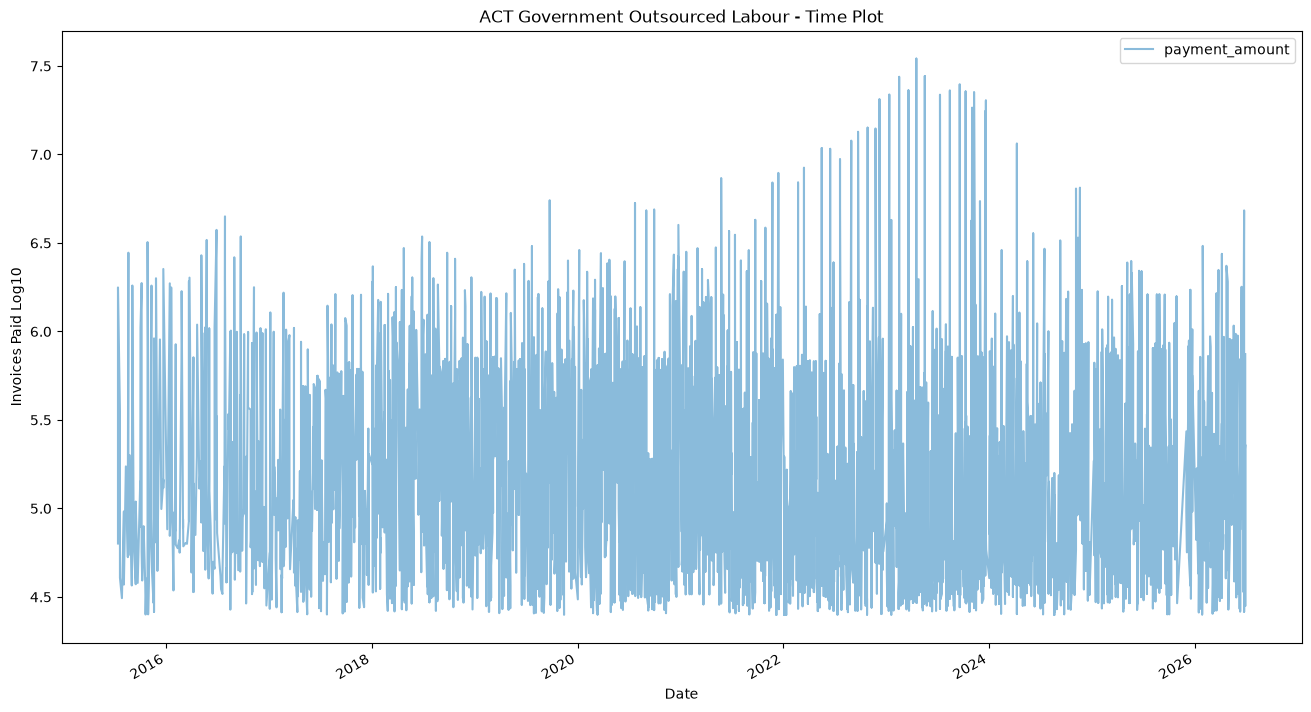

In [63]:
data1_plot.plot(title = 'ACT Government Outsourced Labour - Time Plot', figsize = (16, 9))
plt.ylabel('Invoices Paid Log10')
plt.xlabel('Date')

<div class = "notes">
    <b>Notes:</b>
    <br>According to the website, the database was officially lauched in July 2016. It surprised me to see invoices before then.
    <br>I will drop the invoices prior to 1 July 2016.
    <br>Maybe to remove the $412.5M payment in 2019 for the Canberra Light Rail? I consider this as a major investment that won't happen often. It's more like a noise.
</div>

### 3.4 Seasonal Plots

In [64]:
# define year and month
data1_plot.index = pd.to_datetime(data1_plot.index)
data1_plot['year'] = [x for x in data1_plot.index.year]
data1_plot['month'] = [x for x in data1_plot.index.month]


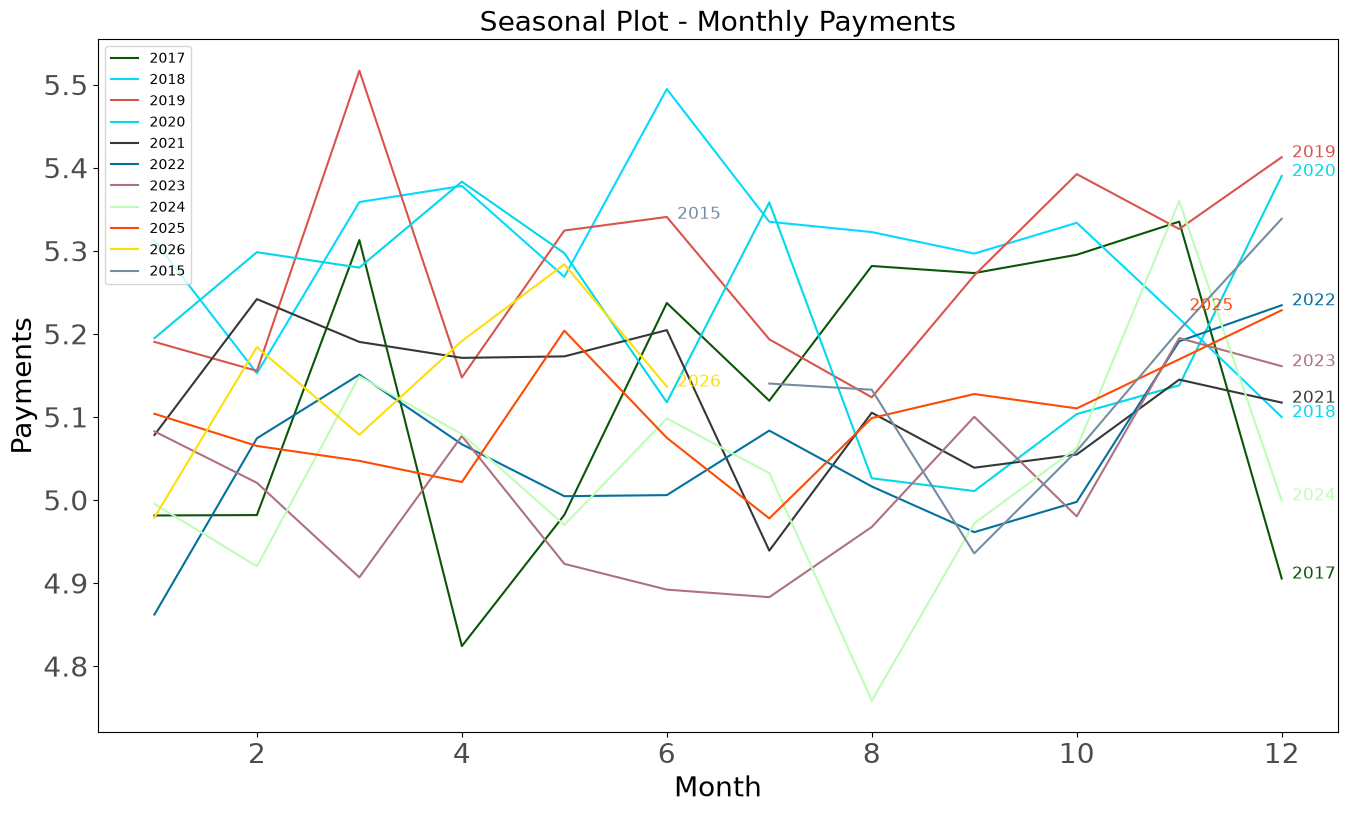

In [76]:
# defining colors palette
np.random.seed(42)
seasonal_plot = data1_plot[['month', 'year', 'payment_amount']].groupby(['month', 'year']).mean()[['payment_amount']].reset_index()
years = seasonal_plot['year'].unique()
colors = np.random.choice(list(mcolors.XKCD_COLORS.keys()), len(years), replace=False)

# Plot
plt.figure(figsize=(16,9))
for i, y in enumerate(years):
    if i > 0:        
        plt.plot('month', 'payment_amount', data=seasonal_plot[seasonal_plot['year'] == y], color=colors[i], label=y)
        plt.text(seasonal_plot.loc[seasonal_plot.year==y, :].shape[0]+0.1, seasonal_plot.loc[seasonal_plot.year==y, 'payment_amount'][-1:].values[0], y, fontsize=12, color=colors[i])

# Setting labels
plt.gca().set(ylabel= 'Invoices Paid Log10', xlabel = 'Month')
plt.yticks(fontsize=20, alpha=.7)
plt.xticks(fontsize=20, alpha=.7)
plt.title("Seasonal Plot - Monthly Payments", fontsize=20)
plt.ylabel('Payments', fontsize=20)
plt.xlabel('Month', fontsize=20)
plt.legend()
plt.show()

### 3.5 Box Plots - Total Payment Amount

Text(0.5, 1.0, 'Boxplot - Invoice Payment Amount')

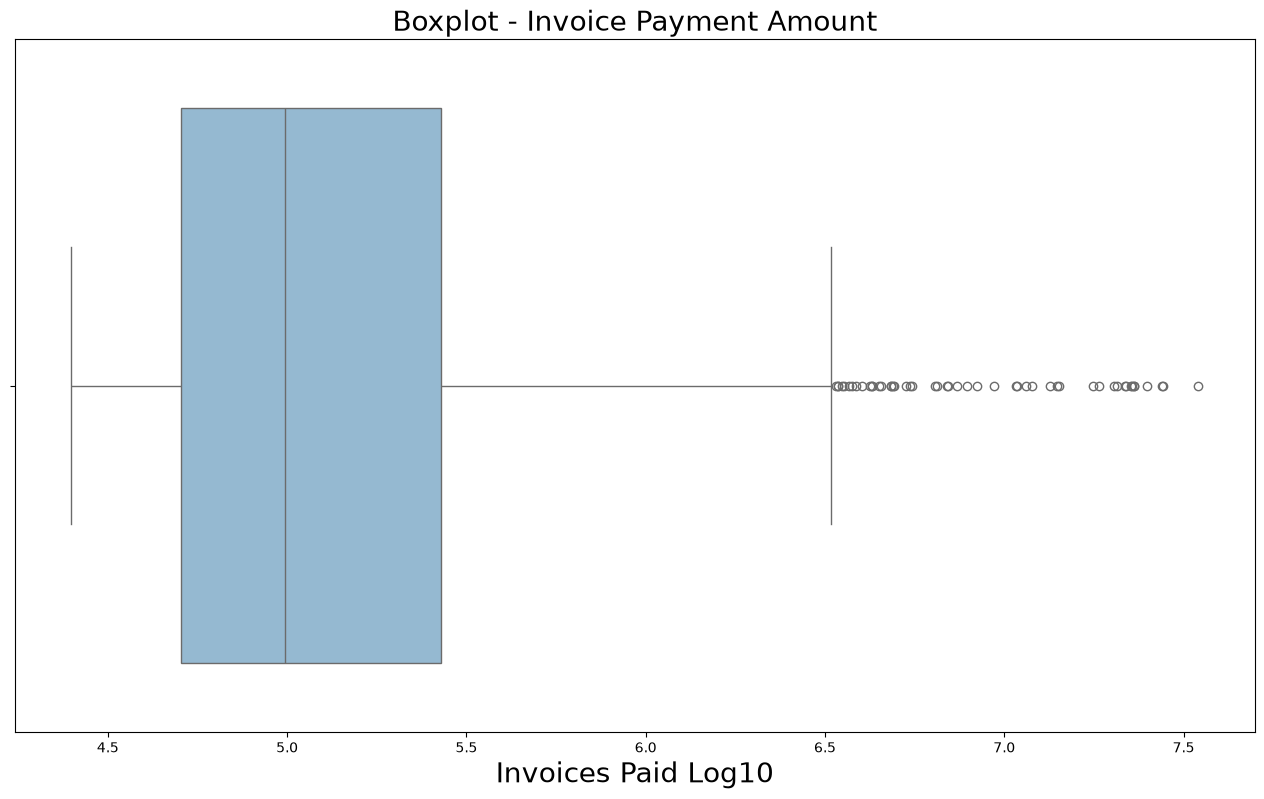

In [66]:
plt.figure(figsize = (16, 9))

sns.boxplot(data = data1_plot, x = 'payment_amount')

plt.xlabel('Invoices Paid Log10', fontsize = 20)

plt.title('Boxplot - Invoice Payment Amount', fontsize = 20)

### 3.6 Box Plots - Month Distribution Sampling 2024 & 2025 

Text(0.5, 0, 'Year Month')

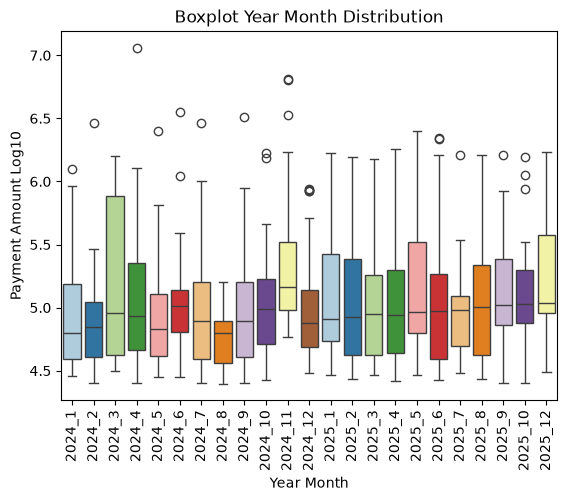

In [67]:
data1_plot['year_month'] = [str(x.year) + '_' + str(x.month) for x in data1_plot.index]


box_plot = data1_plot[(data1_plot['year'] == 2024) | (data1_plot['year'] == 2025)].reset_index().sort_values(by='payment_date').set_index('payment_date')
plt.title('Boxplot Year Month Distribution');
plt.xticks(rotation=90)
plt.xlabel('Year Month')
plt.ylabel('Payment Amount Log10')

sns.boxplot(x='year_month', y='payment_amount', data=box_plot, palette = 'Paired')
plt.ylabel('Payment Amount Log10')
plt.xlabel('Year Month')

### 3.7 Time Series Decomposition

In [68]:
from statsmodels.tsa.seasonal import seasonal_decompose

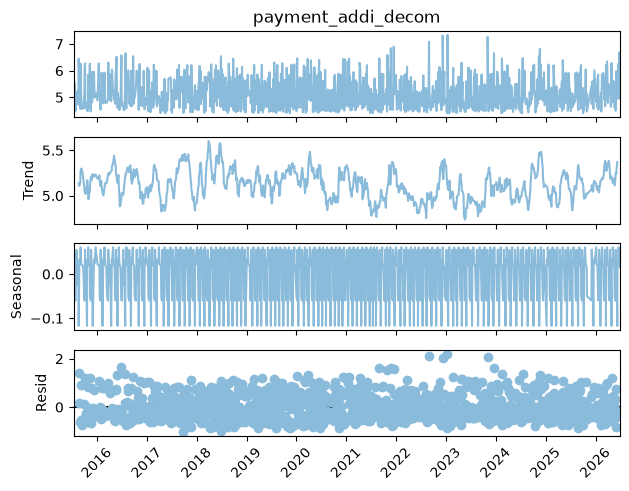

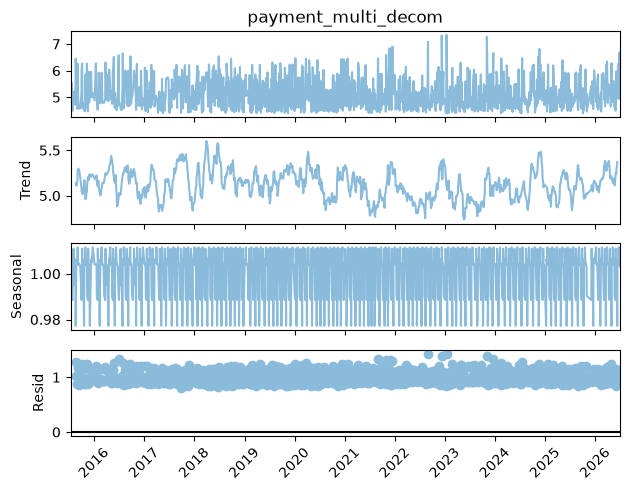

In [69]:
decom_plot = data1_plot.reset_index()
decom_plot = decom_plot.drop_duplicates(subset = ['payment_date']).sort_values(by = 'payment_date')
decom_plot = decom_plot.set_index('payment_date')
decom_plot['payment_addi_decom'] = decom_plot['payment_amount']
decom_plot['payment_multi_decom'] = decom_plot['payment_amount']

# create additive decomposition
result_addi = seasonal_decompose(decom_plot['payment_addi_decom'], model = 'additive', period = 12)

# create multiplicative decomposition
result_multi = seasonal_decompose(decom_plot['payment_multi_decom'], model = 'multiplicative', period = 12)

# plot away
result_addi.plot().suptitle('', fontsize=20)
plt.xticks(rotation=45)
result_multi.plot().suptitle('', fontsize=20)
plt.xticks(rotation=45)
plt.show()

### 3.8 Time Series Decomposition - Sample 2025

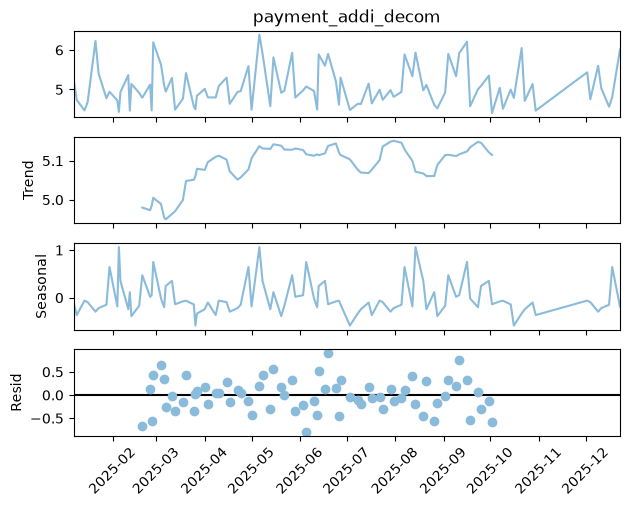

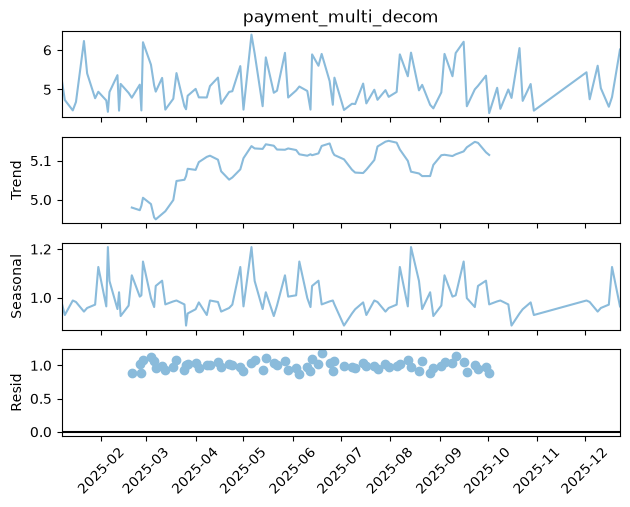

In [70]:
decom_plot = data1_plot[data1_plot['year'] == 2025].reset_index()
decom_plot = decom_plot.drop_duplicates(subset = ['payment_date']).sort_values(by = 'payment_date')
decom_plot = decom_plot.set_index('payment_date')
decom_plot['payment_addi_decom'] = decom_plot['payment_amount']
decom_plot['payment_multi_decom'] = decom_plot['payment_amount']

# create additive decomposition
result_addi = seasonal_decompose(decom_plot['payment_addi_decom'], model = 'additive', period = 30)

# create multiplicative decomposition
result_multi = seasonal_decompose(decom_plot['payment_multi_decom'], model = 'multiplicative', period = 30)

# plot away
result_addi.plot().suptitle('', fontsize=22)
plt.xticks(rotation=45)
result_multi.plot().suptitle('', fontsize=22)
plt.xticks(rotation=45)
plt.show()

### 3.9 Lag Analysis

In [71]:
from statsmodels.graphics.tsaplots import plot_pacf

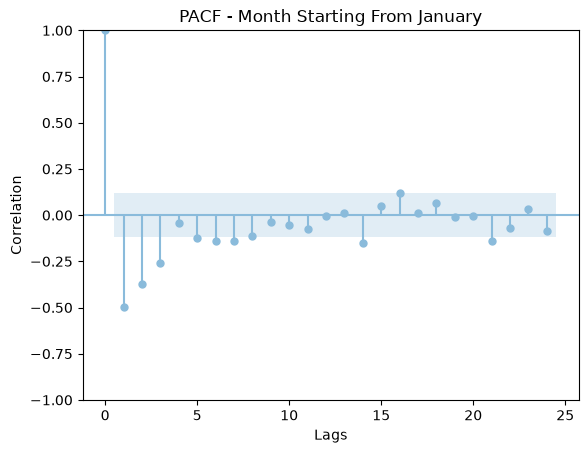

In [72]:
lag_actual = data1_plot['payment_amount']

# plot pacf 
monthly_data = lag_actual[lag_actual.index.month == 1].diff().dropna()
plot_pacf(
            monthly_data, lags = 24, alpha = 0.05 #the confidence interval at 95%
        )
plt.title(f'PACF - Month Starting From January')
plt.ylabel('Correlation')
plt.xlabel('Lags')
plt.show()

<div class = "notes">
    <b>Notes:</b>
    <br>It seems that the correlation of the time-series gets closer to zero at lag of 18. The reasonable cut-off for the modelling is 12 months.
</div>

In [73]:
# data to export

# copy from the data_clean DataFrame
data_export = outsource_df.copy()

# select only four columns reporting_entity, publish_description, payment_date, payment_amount
data_export = data_export.drop(['publish_description'], axis = 1)

# aggregate the payment_amount by reporting_entity, publish_description, payment_date
data_export = data_export.groupby(['services','payment_date'])['payment_amount'].agg('sum').reset_index()

In [74]:
data_export

,services,payment_date,payment_amount
0,CONTRACTOR COSTS,2015-07-14,4.801811
1,CONTRACTOR COSTS,2015-07-21,10.156949
2,CONTRACTOR COSTS,2015-07-28,4.493026
3,CONTRACTOR COSTS,2015-08-04,9.553150
4,CONTRACTOR COSTS,2015-08-11,5.237410
...,...,...,...
1854,LABOUR HIRE COSTS,2026-06-16,10.206209
1855,LABOUR HIRE COSTS,2026-06-19,4.943595
1856,LABOUR HIRE COSTS,2026-06-23,15.503265
1857,LABOUR HIRE COSTS,2026-06-25,5.268845


In [75]:
# export the DataFrame to a csv
# data_export.to_csv('capstone_outsourcing_df.csv', index = False)